# Supplementary Fig S6 · Tile dendrograms, the consensus tree and its blocks

Explains the gene order and blocks of a niche (cited from Methods 3.3 and Supplementary B.3). Breast, the largest
niche of the seed-0 layout (the niche of Fig S1A). User, 4 Nov: dendrograms instead of fine runs; no cut line (the
knee is not shown); show that tile trees are merged into one consensus tree.

* **A** the gene dendrograms (average linkage on 1 - |r|) of three random index tiles of the niche, each in its own
  leaf order; the bar under the leaves colors every gene by its block in the consensus order.
* **B** the consensus tree (average linkage on the niche's mean cophenetic matrix), its leaf order = the niche's gene
  order, the blocks (the four blocks that are subtrees in color and numbered, the others alternating gray), and the niche's mean
  correlation in that order with the blocks outlined.

**Run first:** `R10_block_structure` (`results/block_structure/consensus_example.npz`). Writes `figures/figS6_blocks/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch, Rectangle
from scipy.cluster.hierarchy import dendrogram

import style as ps

FIG = "figS6_blocks"
RES = ROOT / "results" / "block_structure"
CMAP = ps.DIVERGING
VMAX = 0.6
H = 124.0
CHAIN = ("#BDBDBD", "#E8E8E8")

z = np.load(RES / "consensus_example.npz")
perm, blocks, is_clade, markers = z["perm"], z["blocks"], z["is_clade"], z["markers"]
R = z["corr"].astype(float)
p = len(perm)
clade_colors = dict(zip(np.flatnonzero(is_clade).tolist(), ps.niche_palette(int(is_clade.sum()))))
block_color, chain_i = [], 0
for b in range(len(blocks)):
    if is_clade[b]:
        block_color.append(clade_colors[b])
    else:
        block_color.append(CHAIN[chain_i % 2]); chain_i += 1
gene_block = np.empty(p, int)                  # block of every gene (global index)
for b, (a, e) in enumerate(blocks):
    gene_block[perm[a:e]] = b
print(f"niche {int(z['niche'])}: {int(z['n_tiles'])} index tiles, {p} genes, {len(blocks)} blocks "
      f"(sizes {(blocks[:, 1] - blocks[:, 0]).tolist()}); subtrees: "
      f"{[(int(b) + 1, str(markers[b])) for b in np.flatnonzero(is_clade)]}; example tiles {z['tile_rows'].tolist()}")


def draw_tree(ax, Z, lw=0.12, color=ps.MUTED):
    dendrogram(Z, ax=ax, no_labels=True, link_color_func=lambda _: color)
    for c in ax.collections:
        c.set_linewidth(lw)
    ax.set_xlim(0, 10 * p)
    ax.set_xticks([])
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)


def draw_bar(ax, genes_in_order):
    for i, g in enumerate(genes_in_order):
        ax.add_patch(Rectangle((i, 0), 1, 1, fc=block_color[gene_block[g]], ec="none"))
    ax.set_xlim(0, p); ax.set_ylim(0, 1); ax.axis("off")

niche 0: 664 index tiles, 313 genes, 16 blocks (sizes [27, 15, 15, 15, 15, 22, 15, 15, 24, 15, 28, 15, 15, 15, 15, 47]); subtrees: [(8, 'CD3E PTPRC'), (10, 'FCER1G CD68'), (12, 'LUM POSTN'), (16, 'KRT7 ERBB2')]; example tiles [1358, 1456, 1623]


## A · Three tiles' gene dendrograms

figures/figS6_blocks/panels/A.pdf/.png: 64 x 124 mm, 0.1 / 0.3 MB


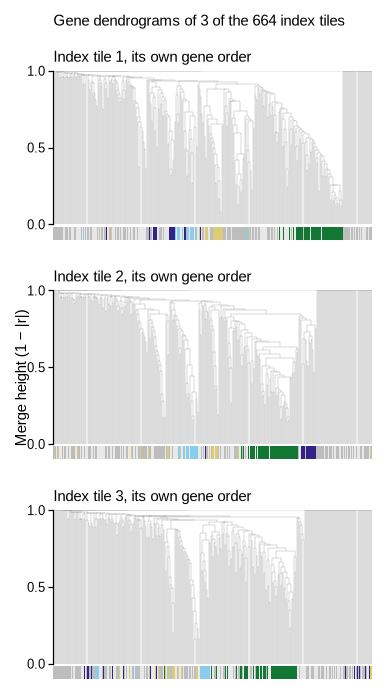

In [2]:
def panel_a(fig):
    W, Hp = ps.size_mm(fig)
    n = len(z["tile_rows"])
    h_tree, h_bar, gap, top = 26.0, 2.2, 9.0, 10.0
    for t in range(n):
        y = top + t * (h_tree + h_bar + gap)
        ax = fig.add_axes([8.0 / W, 1 - (y + h_tree) / Hp, (W - 10.0) / W, h_tree / Hp])
        draw_tree(ax, z["tile_Z"][t])
        ax.set_ylim(0, 1.0)
        ax.set_yticks([0, 0.5, 1])
        ax.tick_params(labelsize=ps.TICK_PT - 1)
        fig.text(8.0 / W, 1 - (y - 1.0) / Hp, f"Index tile {t + 1}, its own gene order", va="bottom",
                 fontsize=ps.TICK_PT)
        bx = fig.add_axes([8.0 / W, 1 - (y + h_tree + h_bar + 0.4) / Hp, (W - 10.0) / W, h_bar / Hp])
        draw_bar(bx, z["tile_leaves"][t])
    fig.text(1.5 / W, 0.5, "Merge height (1 − |r|)", rotation=90, va="center", ha="left", fontsize=ps.TICK_PT)
    fig.text(8.0 / W, 1 - 0.5 / Hp, f"Gene dendrograms of {n} of the {int(z['n_tiles'])} index tiles", va="top",
             fontsize=ps.TICK_PT)


fig = ps.panel(64, H); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · Consensus tree, blocks and mean correlation

figures/figS6_blocks/panels/B.pdf/.png: 114 x 124 mm, 0.3 / 0.5 MB


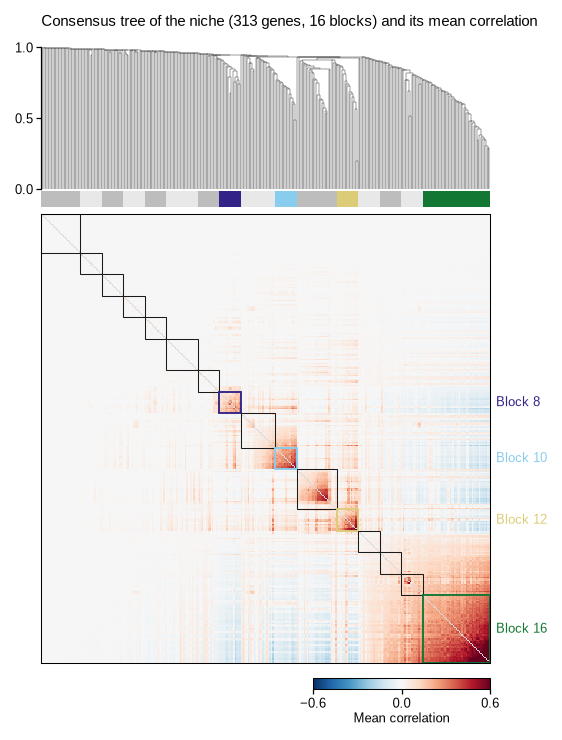

In [3]:
def panel_b(fig):
    W, Hp = ps.size_mm(fig)
    x0, side, h_tree, h_bar, top = 12.0, 76.0, 24.0, 2.6, 6.0
    ax = fig.add_axes([x0 / W, 1 - (top + h_tree) / Hp, side / W, h_tree / Hp])
    draw_tree(ax, z["Z"], lw=0.2, color=ps.INK)
    ax.set_ylim(0, 1.0); ax.set_yticks([0, 0.5, 1]); ax.tick_params(labelsize=ps.TICK_PT - 1)
    y_bar = top + h_tree + 0.4
    bx = fig.add_axes([x0 / W, 1 - (y_bar + h_bar) / Hp, side / W, h_bar / Hp])
    draw_bar(bx, perm)
    y_m = y_bar + h_bar + 1.2
    mx = fig.add_axes([x0 / W, 1 - (y_m + side) / Hp, side / W, side / Hp])
    M = R.copy(); np.fill_diagonal(M, np.nan)
    cmap = plt.get_cmap(CMAP).copy(); cmap.set_bad(ps.LIGHT)
    mx.imshow(M, cmap=cmap, vmin=-VMAX, vmax=VMAX, interpolation="nearest")
    for b, (a, e) in enumerate(blocks):
        clade = bool(is_clade[b])
        mx.add_patch(Rectangle((a - 0.5, a - 0.5), e - a, e - a, fill=False, lw=0.9 if clade else 0.5,
                               ec=block_color[b] if clade else ps.INK))
        if clade:
            g1, g2 = str(markers[b]).split()
            fig.text((x0 + side + 1.0) / W, 1 - (y_m + (a + e) / 2 / p * side) / Hp,
                     f"Block {b + 1}", va="center", fontsize=ps.TICK_PT - 1, color=block_color[b])
    mx.set_xticks([]); mx.set_yticks([])
    for sp in mx.spines.values():
        sp.set_visible(True); sp.set_linewidth(0.5)
    fig.text(x0 / W, 1 - 0.5 / Hp, f"Consensus tree of the niche ({p} genes, {len(blocks)} blocks) and its mean "
             "correlation", va="top", fontsize=ps.TICK_PT)
    cax = fig.add_axes([(x0 + side - 30.0) / W, 1 - (y_m + side + 4.5) / Hp, 30.0 / W, 2.0 / Hp])
    cb = fig.colorbar(ScalarMappable(Normalize(-VMAX, VMAX), CMAP), cax=cax, ticks=[-VMAX, 0, VMAX],
                      orientation="horizontal")
    cb.outline.set_linewidth(0.5); cb.ax.tick_params(labelsize=ps.TICK_PT - 1)
    cb.set_label("Mean correlation", fontsize=ps.TICK_PT - 1, labelpad=1)


fig = ps.panel(114, H); panel_b(fig); ps.save_panel(fig, FIG, "B")

## Full figure

figures/figS6_blocks/figS6_blocks.pdf/.png: 180 x 124 mm, 0.4 / 0.9 MB


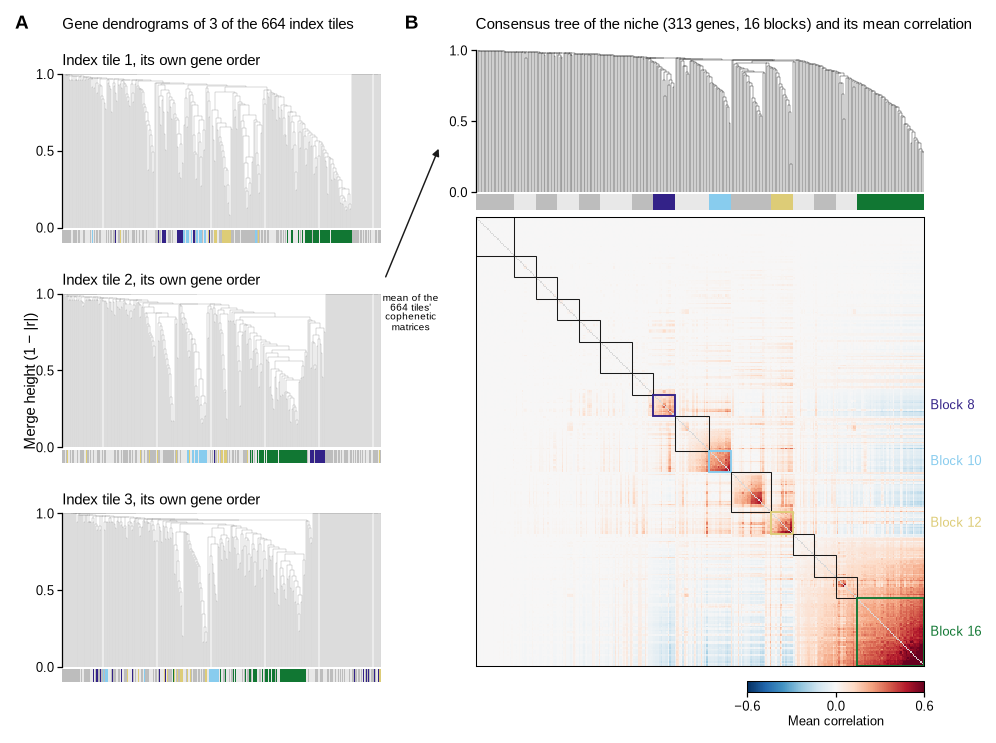

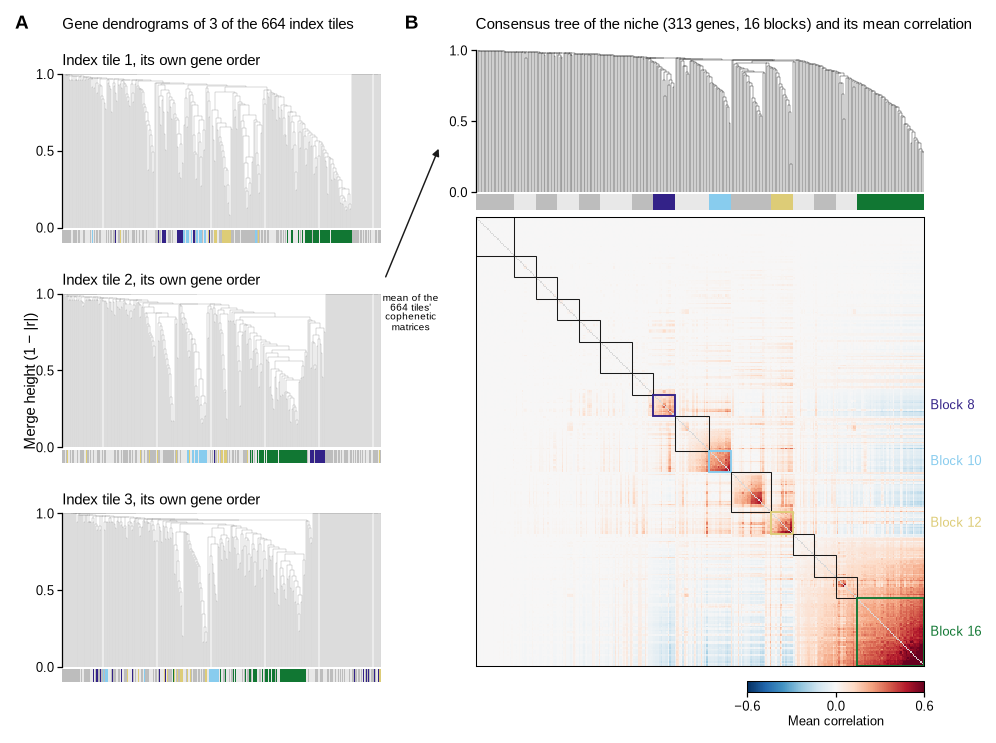

In [4]:
page = ps.page(180, H)
panel_a(ps.place(page, "A", 0, 0, 64, H))
panel_b(ps.place(page, "B", 66, 0, 114, H))
W, Hp = ps.size_mm(page)
page.add_artist(FancyArrowPatch((62.5 / W, 1 - 45.0 / Hp), (72.0 / W, 1 - 22.0 / Hp), transform=page.transFigure,
                                arrowstyle="-|>", mutation_scale=7, lw=0.7, color=ps.INK))
page.text(67.0 / W, 1 - 47.0 / Hp, "mean of the\n664 tiles'\ncophenetic\nmatrices", ha="center", va="top",
          fontsize=ps.TICK_PT - 2, linespacing=1.0)
ps.save_figure(page, FIG)
page